# 02 — Experiment A (Baseline Classifier), TreeSHAP Engine & 95th-Percentile Monitor Calibration
Trains `IDSEngine` (XGBoost + TreeSHAP), evaluates per-class precision/recall/F1 on clean validation traffic, inspects class-conditional SHAP profiles ($R_c$), and freezes `M1`–`M4` thresholds at a matched **5% False-Alarm Rate**.

In [1]:
import sys
import json
from pathlib import Path

ML_SERVICE_ROOT = Path.cwd().resolve()
if ML_SERVICE_ROOT.name == "notebooks":
    ML_SERVICE_ROOT = ML_SERVICE_ROOT.parent
if str(ML_SERVICE_ROOT) not in sys.path:
    sys.path.insert(0, str(ML_SERVICE_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
from src.config import settings
from src.logger import setup_logging

setup_logging()
print("Connected to ML Service Root:", ML_SERVICE_ROOT)
from sklearn.metrics import confusion_matrix
from src.service.train_and_calibrate import run_training_and_calibration
from src.service.model_engine import IDSEngine
from src.service.monitors import DriftMonitorSuite

Connected to ML Service Root: C:\Users\Dell\Desktop\ea-idrs\ml-service


In [2]:
model_path = settings.ARTIFACTS_DIR / "xgb_ids.joblib"
if not model_path.exists():
    run_training_and_calibration()

engine = IDSEngine.load(settings.ARTIFACTS_DIR / "xgb_ids.joblib")
monitor = DriftMonitorSuite.load(
    settings.ARTIFACTS_DIR / "reference_profile.joblib",
    settings.ARTIFACTS_DIR / "thresholds.json",
    min_bucket_samples=settings.MIN_BUCKET_SAMPLES,
)
print("Frozen 95th-Percentile Thresholds (Matched 5% FAR):")
for k, v in monitor.thresholds.__dict__.items():
    print(f"  {k}: {v:.5f}")

Frozen 95th-Percentile Thresholds (Matched 5% FAR):
  m1_threshold: 2.91083
  m2_threshold: 2.91083
  m3_threshold: 2.42508
  m4_threshold: 2.27049


### 1. Experiment A: Baseline Per-Class Classification Metrics & Confusion Matrix

,precision,recall,f1-score,support
BENIGN,1.0000,0.9995,0.9997,340696.0000
Bot,0.7192,0.9966,0.8355,293.0000
BruteForce,0.9990,1.0000,0.9995,2075.0000
DDoS,0.9997,0.9997,0.9997,19204.0000
DoS,0.9984,1.0000,0.9992,37756.0000
PortScan,1.0000,1.0000,1.0000,23820.0000
WebAttack,1.0000,0.9693,0.9844,326.0000
accuracy,0.9995,0.9995,0.9995,0.9995
macro avg,0.9595,0.9950,0.9740,424170.0000
weighted avg,0.9996,0.9995,0.9996,424170.0000


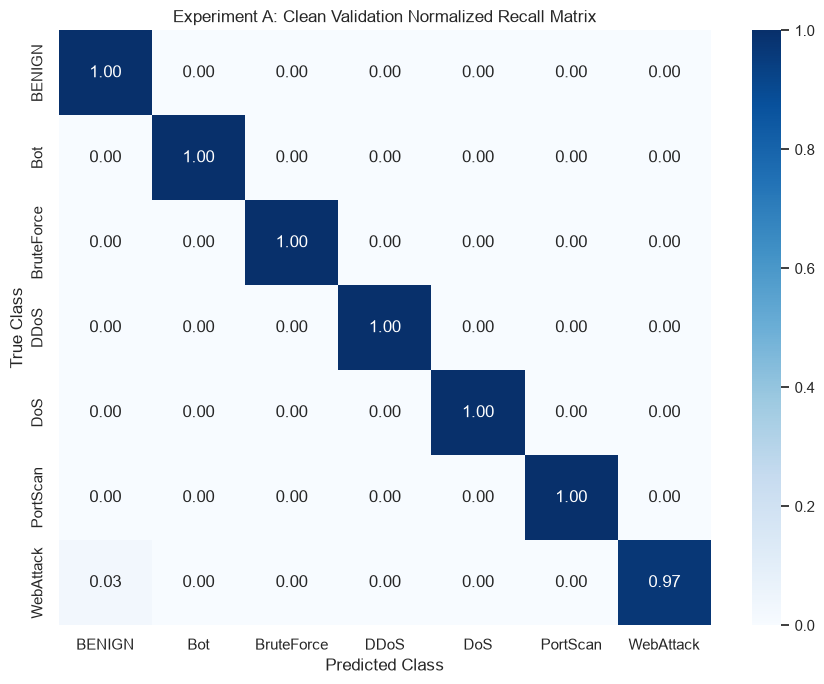

In [3]:
with open(settings.ARTIFACTS_DIR / "baseline_metrics.json", encoding="utf-8") as f:
    report = json.load(f)
display(pd.DataFrame(report).T.round(4))

with open(settings.SPLITS_DIR / "split_metadata.json", encoding="utf-8") as f:
    feature_cols = json.load(f)["feature_cols"]

val_df = pd.read_parquet(settings.SPLITS_DIR / "val_clean.parquet")
X_val = val_df[feature_cols].to_numpy(dtype=np.float32)
y_val = val_df["target"].to_numpy()
y_pred = engine.label_encoder.inverse_transform(engine.model.predict(X_val))

classes = engine.label_encoder.classes_
cm = confusion_matrix(y_val, y_pred, labels=classes, normalize="true")

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title("Experiment A: Clean Validation Normalized Recall Matrix")
plt.ylabel("True Class")
plt.xlabel("Predicted Class")
plt.tight_layout()
plt.show()

### 2. Top-15 Features Monitored by `M1` & `M4` and Class-Conditional SHAP Signatures ($R_c$)

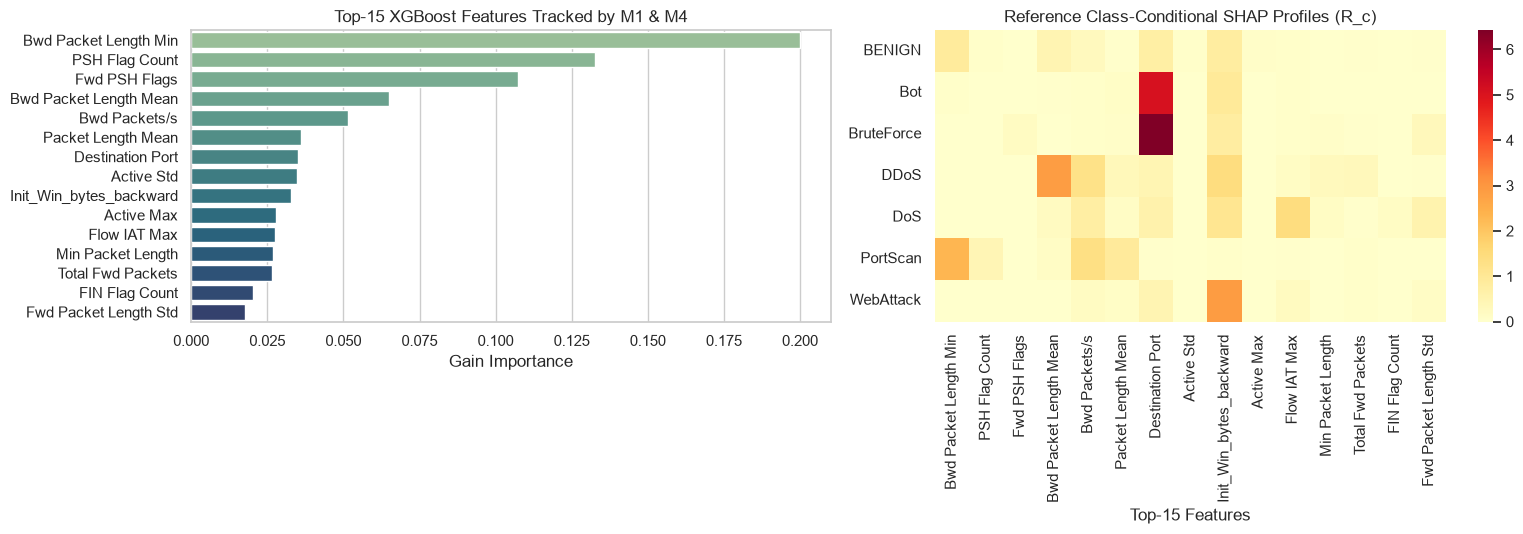

In [4]:
top_idx = monitor.ref.top_feature_indices
top_names = [feature_cols[i] for i in top_idx]
top_imp = engine.model.feature_importances_[top_idx]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sns.barplot(x=top_imp, y=top_names, ax=axes[0], hue=top_names, palette="crest", legend=False)
axes[0].set_title("Top-15 XGBoost Features Tracked by M1 & M4")
axes[0].set_xlabel("Gain Importance")

mean_abs_shap_matrix = []
valid_c_names = []
for c_idx, c_name in enumerate(classes):
    shap_c = monitor.ref.shap_by_class.get(c_idx)
    if shap_c is not None and len(shap_c) > 0:
        mean_abs_shap_matrix.append(np.mean(np.abs(shap_c[:, top_idx]), axis=0))
        valid_c_names.append(c_name)

shap_df = pd.DataFrame(mean_abs_shap_matrix, index=valid_c_names, columns=top_names)
sns.heatmap(shap_df, cmap="YlOrRd", ax=axes[1])
axes[1].set_title("Reference Class-Conditional SHAP Profiles (R_c)")
axes[1].set_xlabel("Top-15 Features")
plt.tight_layout()
plt.show()

### 3. Verify Empirical False-Alarm Rate (~5%) on Clean Validation Windows

In [5]:
step = settings.WINDOW_SIZE
val_records = []
for w_idx, start in enumerate(range(0, len(X_val) - step + 1, step)):
    X_w = X_val[start : start + step]
    probs_w, _, shap_w, shap_preds_w = engine.predict_and_explain(X_w, window_seed=w_idx)
    val_records.append(monitor.evaluate_window(X_w, probs_w, shap_preds_w, shap_w))

val_eval_df = pd.DataFrame(val_records)
for m in ["m1", "m2", "m3", "m4"]:
    far = val_eval_df[f"{m}_alert"].mean() * 100.0
    print(f"Clean Validation Empirical FAR ({m.upper()}): {far:.2f}% (Target: 5.00%)")

Clean Validation Empirical FAR (M1): 4.72% (Target: 5.00%)
Clean Validation Empirical FAR (M2): 4.72% (Target: 5.00%)
Clean Validation Empirical FAR (M3): 4.72% (Target: 5.00%)
Clean Validation Empirical FAR (M4): 2.83% (Target: 5.00%)
